In [1]:
# Install plotly
!pip install plotly

# Import everything
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

print("All libraries loaded!")

All libraries loaded!


In [3]:
# Load your cleaned dataset from Task 1
df = pd.read_csv('/mnt/software_requirements_cleaned.csv')

# Quick look
print('Shape:', df.shape)
print()
print('First 5 rows:')
print(df.head())
print()
print('Column types:')
print(df.dtypes)

Shape: (527, 5)

First 5 rows:
  Type                                        Description  Type_encoded  \
0   PE  The system shall refresh the display every 60 ...             7   
1   LF  The application shall match the color of the s...             4   
2   US  If projected  the data must be readable.  On a...            11   
3    A  The product shall be available during normal b...             0   
4   US  If projected  the data must be understandable....            11   

   requirement_length  requirement_length_scaled  
0                  54                  -1.033178  
1                  96                  -0.338042  
2                 159                   0.704661  
3                 196                   1.317043  
4                 203                   1.432898  

Column types:
Type                          object
Description                   object
Type_encoded                   int64
requirement_length             int64
requirement_length_scaled    float64
dtype: objec

In [4]:
# Summary statistics for all numerical columns
print("=== Summary Statistics ===")
print(df.describe())

# Also check how many of each requirement type exist
print("\n=== Requirement Type Distribution ===")
print(df['Type'].value_counts())

=== Summary Statistics ===
       Type_encoded  requirement_length  requirement_length_scaled
count    527.000000          527.000000                 527.000000
mean       4.829222          106.683112                  -0.161228
std        3.888325           42.387989                   0.701557
min        0.000000           37.000000                  -1.314542
25%        1.000000           75.000000                  -0.685610
50%        4.000000           98.000000                  -0.304940
75%        9.000000          130.500000                   0.232962
max       11.000000          231.000000                   1.896322

=== Requirement Type Distribution ===
Type
F     198
US     61
O      55
SE     54
PE     52
LF     32
A      20
SC     20
MN     14
L      10
FT      9
PO      2
Name: count, dtype: int64


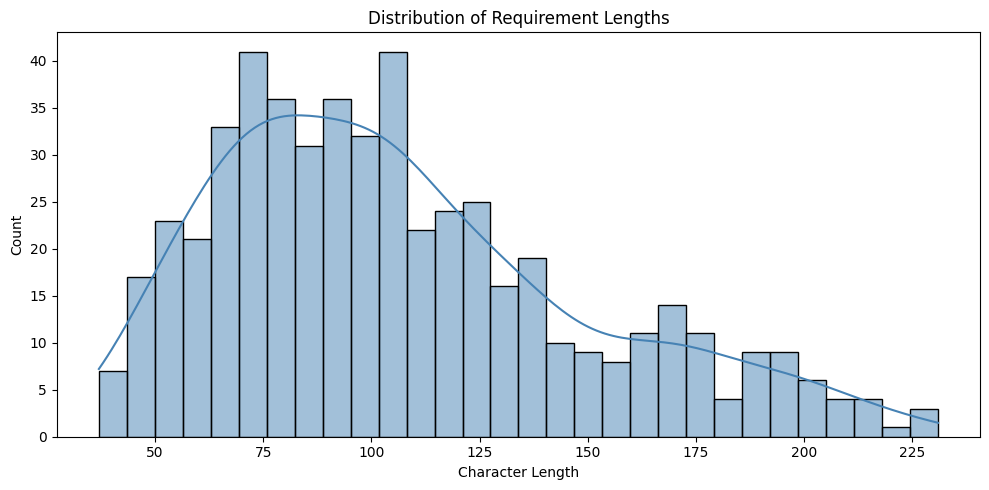

Histogram saved!


In [5]:
# Histogram of requirement lengths
plt.figure(figsize=(10, 5))
sns.histplot(df['requirement_length'], bins=30, kde=True, color='steelblue')
plt.title('Distribution of Requirement Lengths')
plt.xlabel('Character Length')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('histogram_requirement_length.png')
plt.show()
print("Histogram saved!")

/tmp/ipykernel_1735/4166057683.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Type', y='requirement_length', palette='Set2')


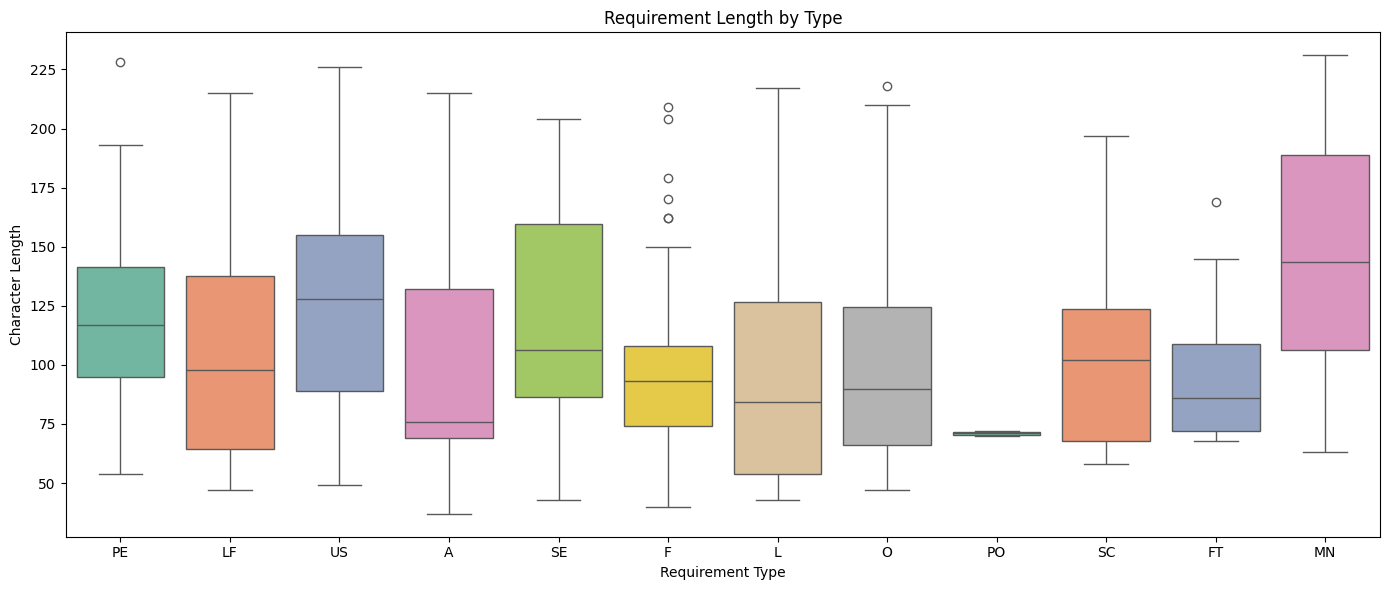

Boxplot saved!


In [6]:
# Boxplot — requirement length broken down by type
plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x='Type', y='requirement_length', palette='Set2')
plt.title('Requirement Length by Type')
plt.xlabel('Requirement Type')
plt.ylabel('Character Length')
plt.tight_layout()
plt.savefig('boxplot_by_type.png')
plt.show()
print("Boxplot saved!")

In [7]:
# Count of each requirement type
type_counts = df['Type'].value_counts().reset_index()
type_counts.columns = ['Type', 'Count']

# Interactive bar chart with Plotly
fig = px.bar(
    type_counts,
    x='Type',
    y='Count',
    color='Type',
    title='Requirement Type Distribution (Interactive)',
    labels={'Type': 'Requirement Type', 'Count': 'Number of Requirements'},
    text='Count'
)
fig.update_traces(textposition='outside')
fig.show()

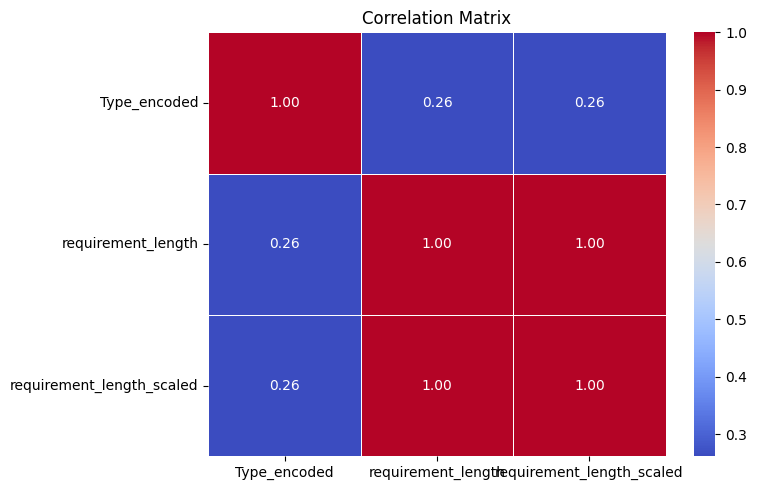

Correlation matrix saved!


In [8]:
# Correlation matrix on numerical columns only
plt.figure(figsize=(8, 5))
corr = df[['Type_encoded', 'requirement_length', 'requirement_length_scaled']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.savefig('correlation_matrix.png')
plt.show()
print("Correlation matrix saved!")

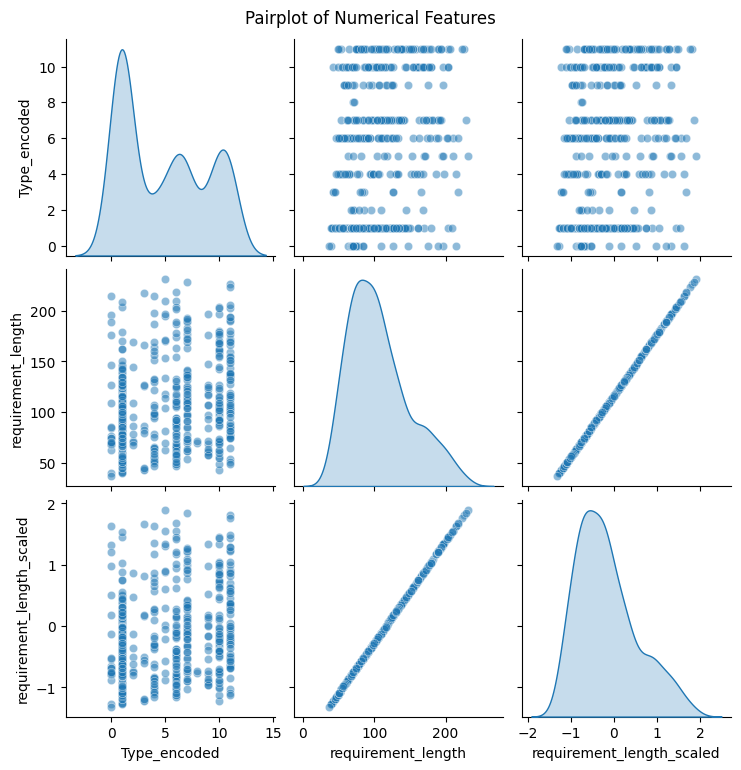

Pairplot saved!


In [9]:
# Pairplot
sns.pairplot(
    df[['Type_encoded', 'requirement_length', 'requirement_length_scaled']],
    diag_kind='kde',
    plot_kws={'alpha': 0.5}
)
plt.suptitle('Pairplot of Numerical Features', y=1.02)
plt.savefig('pairplot.png')
plt.show()
print("Pairplot saved!")

In [10]:
# Average requirement length per type
print("=== Average Requirement Length per Type ===")
avg_length = df.groupby('Type')['requirement_length'].mean().sort_values(ascending=False)
print(avg_length)

# Most and least common types
print("\n=== Most Common Type ===")
print(df['Type'].value_counts().idxmax(), "→", df['Type'].value_counts().max(), "requirements")

print("\n=== Least Common Type ===")
print(df['Type'].value_counts().idxmin(), "→", df['Type'].value_counts().min(), "requirements")

# Skewness
print("\n=== Skewness of Requirement Length ===")
print(round(df['requirement_length'].skew(), 2))
print("(Positive = right skewed = most requirements are short, few are very long)")

=== Average Requirement Length per Type ===
Type
MN    143.714286
US    127.278689
PE    123.096154
SE    117.074074
LF    106.187500
O     103.218182
SC    103.150000
A     102.100000
L     101.700000
FT     99.333333
F      93.383838
PO     71.000000
Name: requirement_length, dtype: float64

=== Most Common Type ===
F → 198 requirements

=== Least Common Type ===
PO → 2 requirements

=== Skewness of Requirement Length ===
0.78
(Positive = right skewed = most requirements are short, few are very long)


In [11]:
# Download all saved images
from google.colab import files
files.download('histogram_requirement_length.png')
files.download('boxplot_by_type.png')
files.download('correlation_matrix.png')
files.download('pairplot.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>